# Part 2: Classification and Model Improvement

## Breast Cancer Classification Using Logistic Regression

Objective: To develop and evaluate a supervised machine-learning model for classifying breast tumours as malignant or benign.

In [1]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Load the Breast Cancer Wisconsin dataset from Kaggle
df = pd.read_csv("data.csv")

# Display the first five observations
print(df.head())

# Display the dimensions of the dataset
print("Dataset shape:", df.shape)

# Display the number of malignant and benign cases
print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())


         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

## 1. Dataset Inspection and Quality Assessment

The dataset is examined to determine its dimensions, variable types, missing values, duplicate observations and class distribution before data preparation and model development.

In [2]:
# Examine the dataset dimensions
print("Dataset dimensions:", df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Identify missing values in each column
print("\nMissing values per column:")
print(df.isnull().sum())

# Count duplicate observations
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Examine the distribution of diagnostic classes
print("\nDiagnosis class distribution:")
print(df["diagnosis"].value_counts())

# Calculate the percentage of each class
print("\nDiagnosis class percentages:")
print(df["diagnosis"].value_counts(normalize=True) * 100)


Dataset dimensions: (569, 33)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569

In [3]:
# Summarise the dataset's initial data quality
print("DATA QUALITY SUMMARY")
print("--------------------")

print("Observations:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns containing missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())

print("\nDiagnosis percentages:")
print(df["diagnosis"].value_counts(normalize=True) * 100)


DATA QUALITY SUMMARY
--------------------
Observations: 569
Columns: 33

Columns containing missing values:
Unnamed: 32    569
dtype: int64

Total missing values:
569

Duplicate rows:
0

Diagnosis distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Diagnosis percentages:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


## 2. Data Cleaning

The dataset is prepared for analysis by removing the entirely empty column and excluding the record identifier from the modelling dataset. The original dataset's dimensions and missing values have already been documented.

In [4]:
# Create a copy to preserve the original dataset
df_clean = df.copy()

# Remove the entirely empty column
df_clean = df_clean.drop(columns=["Unnamed: 32"])

# Remove the record identifier, which is not a predictor
df_clean = df_clean.drop(columns=["id"])

# Verify the cleaned dataset
print("Cleaned dataset dimensions:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum().sum())

print("\nFirst five observations:")
display(df_clean.head())

Cleaned dataset dimensions: (569, 31)

Remaining missing values:
0

First five observations:


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Exploratory Data Analysis (EDA)

### 3.1 Descriptive Statistics

Descriptive statistics are calculated to examine the central tendency, variability and range of the numerical tumour characteristics.

In [5]:
# Select the numerical predictor variables
numerical_features = df_clean.drop(columns=["diagnosis"])

# Calculate descriptive statistics for the predictors
descriptive_stats = numerical_features.describe()

# Display the descriptive statistics
display(descriptive_stats.round(3))

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,...,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063,...,16.269,25.677,107.261,880.583,0.132,0.254,0.272,0.115,0.290,0.084
std,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007,...,4.833,6.146,33.603,569.357,0.023,0.157,0.209,0.066,0.062,0.018
min,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050,...,7.930,12.020,50.410,185.200,0.071,0.027,0.000,0.000,0.156,0.055
25%,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058,...,13.010,21.080,84.110,515.300,0.117,0.147,0.114,0.065,0.250,0.071
50%,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062,...,14.970,25.410,97.660,686.500,0.131,0.212,0.227,0.100,0.282,0.080
75%,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066,...,18.790,29.720,125.400,1084.000,0.146,0.339,0.383,0.161,0.318,0.092
max,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097,...,36.040,49.540,251.200,4254.000,0.223,1.058,1.252,0.291,0.664,0.208


### 3.2 Diagnosis Class Distribution

A bar chart is used to visualise the distribution of benign and malignant diagnoses and assess the degree of class imbalance in the dataset.

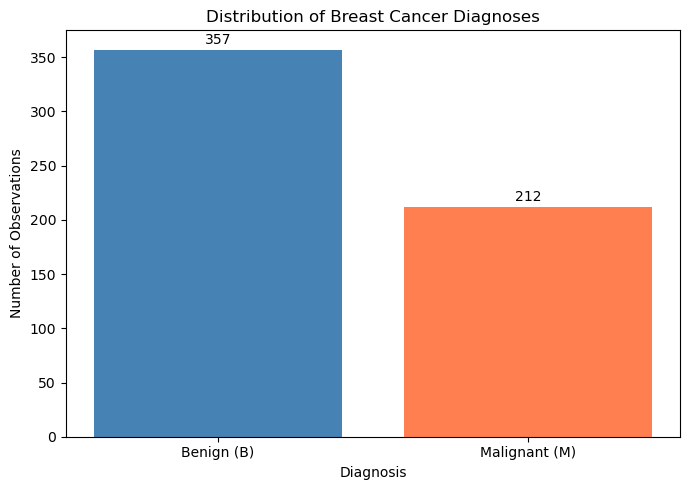

In [6]:
# Import matplotlib for data visualisation
import matplotlib.pyplot as plt

# Count observations in each diagnosis category
diagnosis_counts = df_clean["diagnosis"].value_counts()

# Create a bar chart
plt.figure(figsize=(7, 5))

bars = plt.bar(
    diagnosis_counts.index,
    diagnosis_counts.values,
    color=["steelblue", "coral"]
)

# Add the number of observations above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

# Add chart title and axis labels
plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Observations")

# Replace abbreviated diagnosis labels
plt.xticks([0, 1], ["Benign (B)", "Malignant (M)"])

# Display the chart
plt.tight_layout()
plt.show()


### 3.3 Distribution of Selected Tumour Characteristics

Histograms are used to examine the distributions of selected numerical features, including radius, texture, area and concavity. These visualisations help identify skewness, variability and potential differences in the characteristics of the observations.

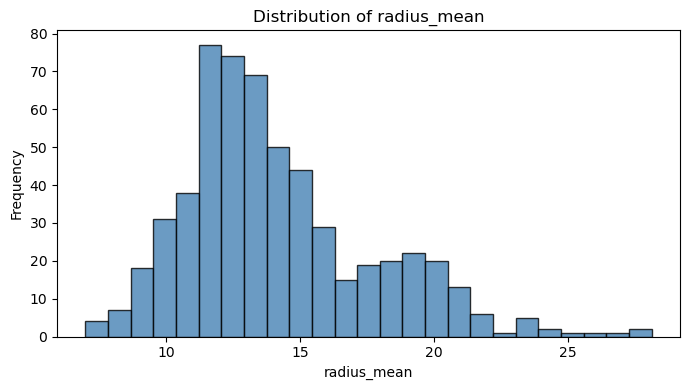

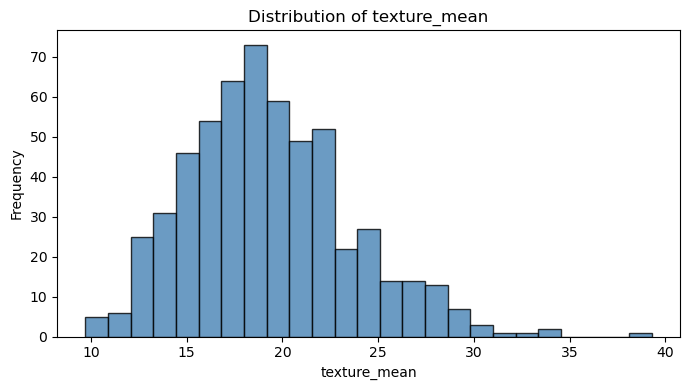

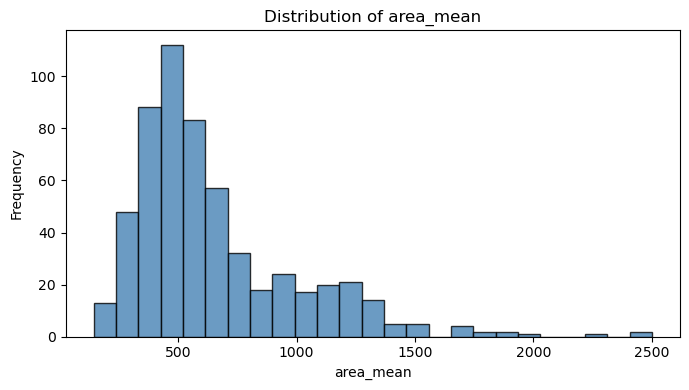

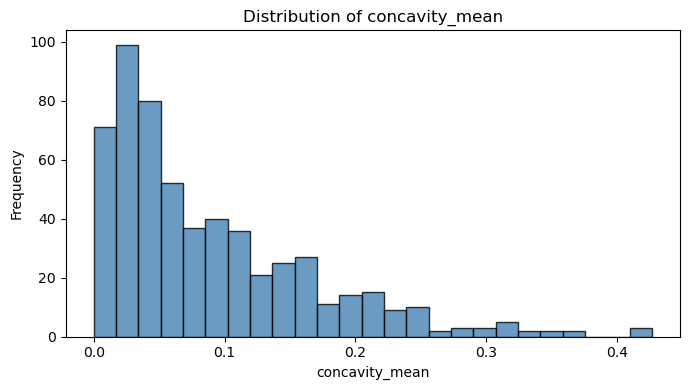

In [7]:
# Select four numerical features for distribution analysis
selected_features = [
    "radius_mean",
    "texture_mean",
    "area_mean",
    "concavity_mean"
]

# Create a separate histogram for each feature
for feature in selected_features:

    plt.figure(figsize=(7, 4))

    plt.hist(
        df_clean[feature],
        bins=25,
        color="steelblue",
        edgecolor="black",
        alpha=0.8
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### 3.4 Outlier Analysis and Comparison by Diagnosis

Boxplots are used to examine the distributions of selected tumour characteristics for benign and malignant observations. They allow comparison of medians, variability and potential outliers between the two diagnostic categories.

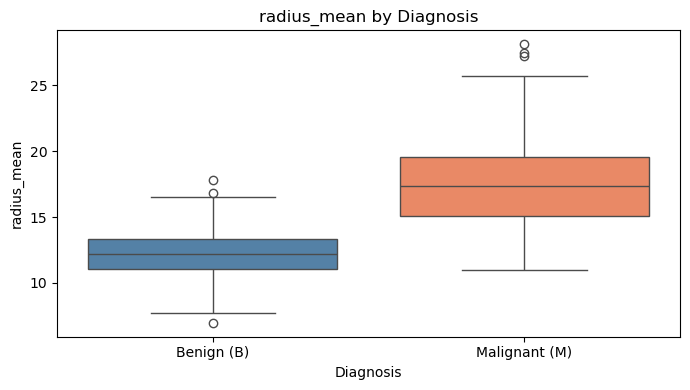

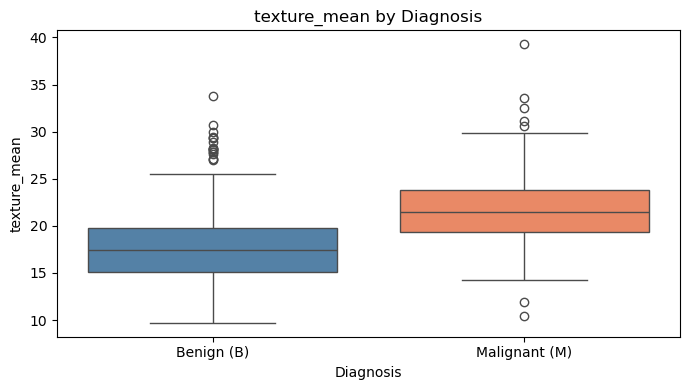

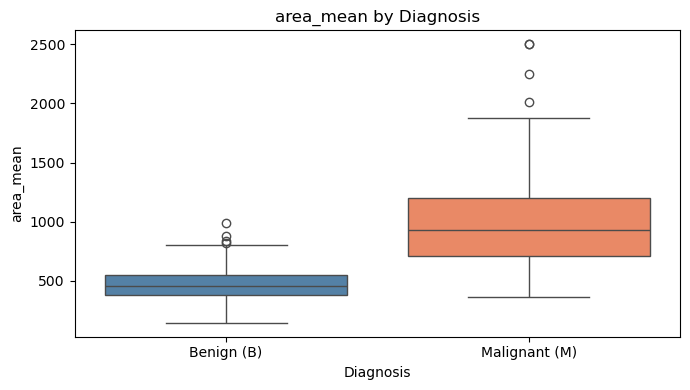

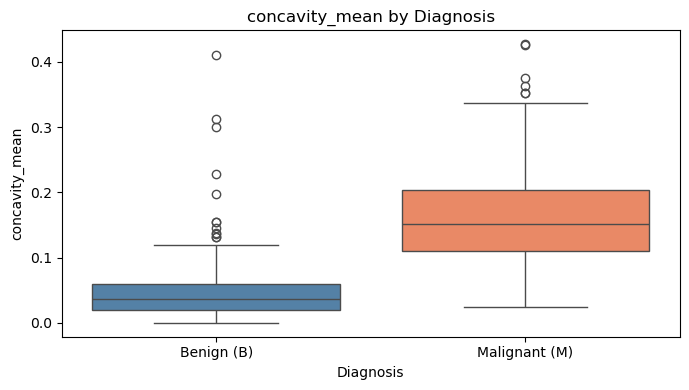

In [8]:
# Import the libraries needed for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical features for comparison
selected_features = [
    "radius_mean",
    "texture_mean",
    "area_mean",
    "concavity_mean"
]

# Create a separate boxplot for each feature
for feature in selected_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df_clean,
        x="diagnosis",
        y=feature,
        order=["B", "M"],
        hue="diagnosis",
        hue_order=["B", "M"],
        palette={"B": "steelblue", "M": "coral"},
        legend=False
    )

    plt.title(f"{feature} by Diagnosis")
    plt.xlabel("Diagnosis")
    plt.ylabel(feature)
    plt.xticks([0, 1], ["Benign (B)", "Malignant (M)"])

    plt.tight_layout()
    plt.show()

### 3.5 Correlation Analysis

Correlation analysis is conducted to examine the relationships between numerical tumour characteristics and identify potential multicollinearity. Pearson correlation coefficients are calculated for the 30 numerical predictors, and a heatmap is used to visualise the strength and direction of these relationships. The findings will inform subsequent feature selection and Logistic Regression model development.

In [9]:
# Select the 30 numerical predictor variables
# Exclude diagnosis and any non-predictive identifiers
X_eda = df.drop(columns=["diagnosis", "id", "Unnamed: 32"], errors="ignore")

# Calculate Pearson correlation coefficients
correlation_matrix = X_eda.corr(method="pearson")

# Display the correlation matrix
print("Correlation matrix dimensions:", correlation_matrix.shape)
display(correlation_matrix.round(2))

Correlation matrix dimensions: (30, 30)


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
radius_mean,1.00,0.32,1.00,0.99,0.17,0.51,0.68,0.82,0.15,-0.31,...,0.97,0.30,0.97,0.94,0.12,0.41,0.53,0.74,0.16,0.01
texture_mean,0.32,1.00,0.33,0.32,-0.02,0.24,0.30,0.29,0.07,-0.08,...,0.35,0.91,0.36,0.34,0.08,0.28,0.30,0.30,0.11,0.12
perimeter_mean,1.00,0.33,1.00,0.99,0.21,0.56,0.72,0.85,0.18,-0.26,...,0.97,0.30,0.97,0.94,0.15,0.46,0.56,0.77,0.19,0.05
area_mean,0.99,0.32,0.99,1.00,0.18,0.50,0.69,0.82,0.15,-0.28,...,0.96,0.29,0.96,0.96,0.12,0.39,0.51,0.72,0.14,0.00
smoothness_mean,0.17,-0.02,0.21,0.18,1.00,0.66,0.52,0.55,0.56,0.58,...,0.21,0.04,0.24,0.21,0.81,0.47,0.43,0.50,0.39,0.50
compactness_mean,0.51,0.24,0.56,0.50,0.66,1.00,0.88,0.83,0.60,0.57,...,0.54,0.25,0.59,0.51,0.57,0.87,0.82,0.82,0.51,0.69
concavity_mean,0.68,0.30,0.72,0.69,0.52,0.88,1.00,0.92,0.50,0.34,...,0.69,0.30,0.73,0.68,0.45,0.75,0.88,0.86,0.41,0.51
concave points_mean,0.82,0.29,0.85,0.82,0.55,0.83,0.92,1.00,0.46,0.17,...,0.83,0.29,0.86,0.81,0.45,0.67,0.75,0.91,0.38,0.37
symmetry_mean,0.15,0.07,0.18,0.15,0.56,0.60,0.50,0.46,1.00,0.48,...,0.19,0.09,0.22,0.18,0.43,0.47,0.43,0.43,0.70,0.44
fractal_dimension_mean,-0.31,-0.08,-0.26,-0.28,0.58,0.57,0.34,0.17,0.48,1.00,...,-0.25,-0.05,-0.21,-0.23,0.50,0.46,0.35,0.18,0.33,0.77


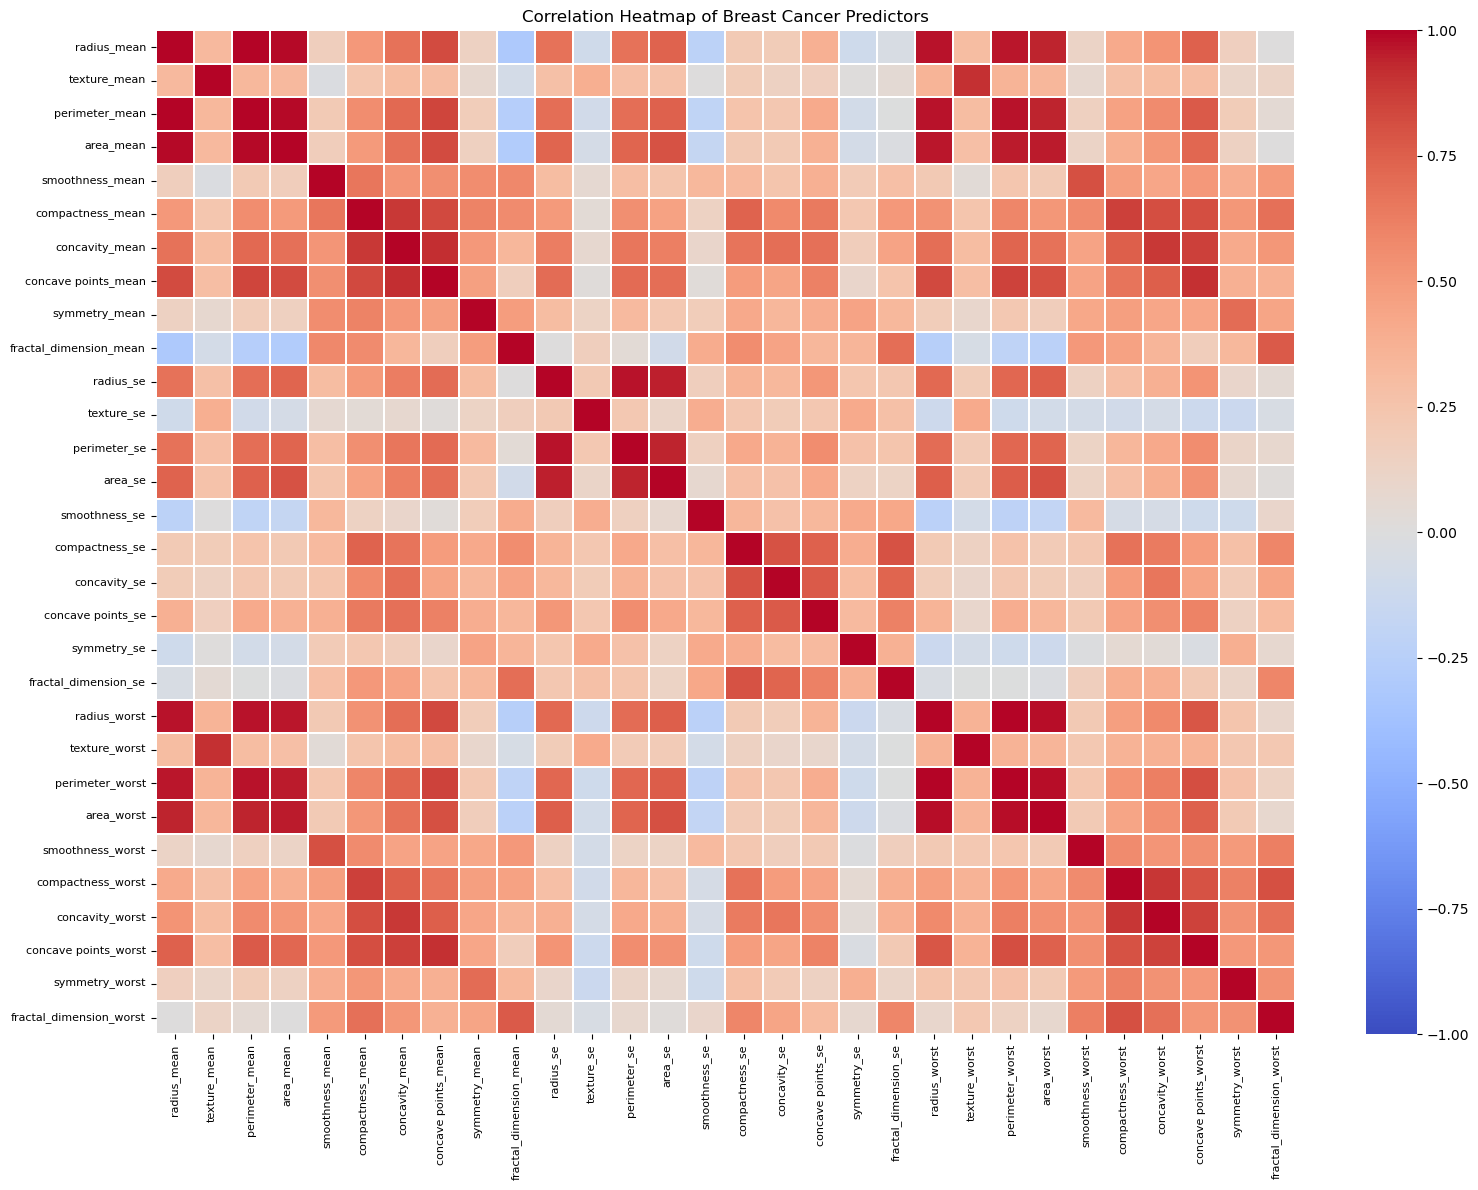

In [10]:
# Visualise correlations between the 30 predictors
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Breast Cancer Predictors")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

In [11]:
# Identify strongly correlated predictor pairs
import numpy as np

# Use absolute correlations to identify strong relationships
absolute_corr = correlation_matrix.abs()

# Select the upper triangle to avoid duplicate pairs
upper_triangle = absolute_corr.where(
    np.triu(np.ones(absolute_corr.shape), k=1).astype(bool)
)

# Extract predictor pairs with correlation above 0.90
strong_pairs = upper_triangle.stack()
strong_pairs = strong_pairs[strong_pairs > 0.90]

# Sort from strongest to weakest
strong_pairs = strong_pairs.sort_values(ascending=False)

print("Predictor pairs with absolute correlation above 0.90:")
display(strong_pairs.to_frame(name="Absolute Correlation"))


Predictor pairs with absolute correlation above 0.90:


,,Absolute Correlation
radius_mean,perimeter_mean,0.997855
radius_worst,perimeter_worst,0.993708
radius_mean,area_mean,0.987357
perimeter_mean,area_mean,0.986507
radius_worst,area_worst,0.984015
perimeter_worst,area_worst,0.977578
radius_se,perimeter_se,0.972794
perimeter_mean,perimeter_worst,0.970387
radius_mean,radius_worst,0.969539
perimeter_mean,radius_worst,0.969476


### 4.5 Feature Selection

In [12]:
# Import the library for splitting the dataset
from sklearn.model_selection import train_test_split

# Define the predictor variables
X = df.drop(columns=["diagnosis", "id", "Unnamed: 32"], errors="ignore")

# Encode the diagnosis:
# Malignant = 1, Benign = 0
y = df["diagnosis"].map({"M": 1, "B": 0})

# Split the dataset into training (80%) and testing (20%)
# Stratification preserves the proportions of malignant and benign cases
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [13]:
# Display the training and testing dataset dimensions
print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])
print("Number of predictors:", X_train.shape[1])

# Display diagnosis distributions
print("\nTraining diagnosis distribution:")
print(y_train.value_counts())

print("\nTesting diagnosis distribution:")
print(y_test.value_counts())

Training observations: 455
Testing observations: 114
Number of predictors: 30

Training diagnosis distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing diagnosis distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [14]:
# Import libraries for feature selection
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

# Select the 10 highest-ranking predictors
selector = SelectKBest(score_func=f_classif, k=10)

# Fit the selector using training data only
selector.fit(X_train, y_train)

# Create a table of feature scores
feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F_Score": selector.scores_,
    "Selected": selector.get_support()
})

In [15]:
# Rank predictors by their F-scores
feature_scores = feature_scores.sort_values(
    by="F_Score",
    ascending=False
)

# Display feature selection results
print("Feature selection results:")
display(feature_scores.round(3))

# Identify the 10 selected predictors
selected_features = X_train.columns[selector.get_support()]

print("\nSelected 10 predictors:")
print(selected_features.tolist())

# Prepare selected features for model training
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

# Confirm dataset dimensions
print("\nTraining shape:", X_train_selected.shape)
print("Testing shape:", X_test_selected.shape)

Feature selection results:


,Feature,F_Score,Selected
27,concave points_worst,733.725,True
22,perimeter_worst,717.246,True
20,radius_worst,692.861,True
7,concave points_mean,684.527,True
2,perimeter_mean,548.413,True
23,area_worst,522.189,True
0,radius_mean,511.275,True
3,area_mean,444.858,True
6,concavity_mean,397.592,True
26,concavity_worst,319.508,True



Selected 10 predictors:
['radius_mean', 'perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean', 'radius_worst', 'perimeter_worst', 'area_worst', 'concavity_worst', 'concave points_worst']

Training shape: (455, 10)
Testing shape: (114, 10)


### 4.6 Feature Standardisation

The 10 selected predictors will be standardised using StandardScaler to ensure that differences in measurement scales do not disproportionately influence the regularised Logistic Regression model.

The scaler will be fitted using the training data only and subsequently applied to both the training and testing datasets to prevent data leakage.

In [16]:
# Import the standardisation tool
from sklearn.preprocessing import StandardScaler

# Initialise the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train_selected)

# Apply the same transformation to the testing data
X_test_scaled = scaler.transform(X_test_selected)

# Confirm the dimensions of the standardised datasets
print("Standardised training shape:", X_train_scaled.shape)
print("Standardised testing shape:", X_test_scaled.shape)

# Check the mean and standard deviation of the training predictors
print("\nTraining feature means:")
print(X_train_scaled.mean(axis=0).round(3))

print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0).round(3))

Standardised training shape: (455, 10)
Standardised testing shape: (114, 10)

Training feature means:
[-0.  0. -0. -0.  0. -0. -0. -0. -0.  0.]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 4.7 Logistic Regression Model Training

A Logistic Regression classification model was trained using the 10 selected and standardised predictors. The model was fitted on the training dataset comprising 455 observations, while the remaining 114 observations were reserved for testing.

The model used L2 regularisation with the default regularisation strength (C = 1.0). Logistic Regression was selected because it is suitable for binary classification and provides an interpretable statistical approach to distinguishing malignant from benign observations.

In [17]:
# Import the Logistic Regression algorithm
from sklearn.linear_model import LogisticRegression

# Initialise the Logistic Regression model
logistic_model = LogisticRegression(
    penalty="l2",
    C=1.0,
    max_iter=1000,
    random_state=42
)

# Train the model using standardised training data
logistic_model.fit(X_train_scaled, y_train)

# Generate predictions for the testing dataset
y_pred = logistic_model.predict(X_test_scaled)

# Confirm that the model was trained successfully
print("Logistic Regression model trained successfully.")

print("\nTraining observations:", X_train_scaled.shape[0])
print("Testing observations:", X_test_scaled.shape[0])

print("\nPredicted diagnosis distribution:")
print("Benign (0):", (y_pred == 0).sum())
print("Malignant (1):", (y_pred == 1).sum())

Logistic Regression model trained successfully.

Training observations: 455
Testing observations: 114

Predicted diagnosis distribution:
Benign (0): 75
Malignant (1): 39


## 5. Model Evaluation

### 5.1 Classification Performance Metrics

The Logistic Regression model will be evaluated using the previously reserved testing dataset of 114 observations. Accuracy, precision, recall and F1-score will be calculated to assess its classification performance.

Particular emphasis will be placed on recall for malignant cases, as incorrectly classifying malignant observations as benign could have serious implications in a clinical setting. Precision will also be considered to assess the proportion of predicted malignant cases that are correctly classified.

In [18]:
# Import classification performance metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

# Display the evaluation results
print("Logistic Regression Model Evaluation")
print("------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Display the full classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

Logistic Regression Model Evaluation
------------------------------------
Accuracy:  0.9561
Precision: 0.9744
Recall:    0.9048
F1-score:  0.9383

Classification Report:
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### 5.2 Confusion Matrix

A confusion matrix was generated to examine the number of correctly and incorrectly classified benign and malignant observations. Particular attention was given to false negatives, representing malignant cases incorrectly predicted as benign.

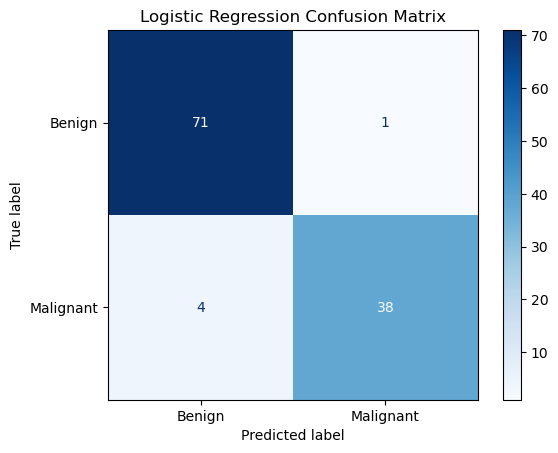

True Negatives: 71
False Positives: 1
False Negatives: 4
True Positives: 38


In [19]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Display classification errors
print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])


### 5.3 Interpretation of Model Performance

The Logistic Regression model achieved an accuracy of 95.61%, precision of 97.44%, recall of 90.48% and an F1-score of 93.83% for malignant classification.

The confusion matrix showed that 71 benign and 38 malignant observations were correctly classified. However, one benign observation was incorrectly classified as malignant, while four malignant observations were incorrectly classified as benign.

The four false negatives are particularly important because they represent malignant observations that the model failed to identify. Although the model demonstrated strong overall classification performance, its malignant recall indicates that further improvement may be beneficial.

Consequently, hyperparameter tuning will be considered to investigate whether malignant recall can be improved without substantially reducing precision.

### 5.4 Hyperparameter Tuning and Model Improvement

Although the initial Logistic Regression model achieved strong overall classification performance, four malignant observations were incorrectly classified as benign.

Hyperparameter tuning was therefore undertaken to investigate whether model performance could be improved, particularly in relation to malignant recall.

GridSearchCV was selected to evaluate different regularisation strengths (C) and class-weight settings using stratified five-fold cross-validation.

The tuning procedure incorporated feature selection and standardisation within a machine learning pipeline to prevent data leakage during cross-validation.

Recall for malignant cases was selected as the primary optimisation metric because false negatives are particularly important in cancer classification.

In [20]:
# Import libraries for model improvement
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create a pipeline to prevent data leakage
pipeline = Pipeline([
    ("feature_selection", SelectKBest(
        score_func=f_classif, k=10
    )),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l2",
        max_iter=1000,
        random_state=42
    ))
])

# Define the hyperparameters to investigate
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

# Use stratified five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Configure the grid search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1
)

# Fit using training data only
grid_search.fit(X_train, y_train)

# Display the best parameters
print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation recall:")
print(round(grid_search.best_score_, 4))

# Store the best model
best_model = grid_search.best_estimator_


Best hyperparameters:
{'classifier__C': 10, 'classifier__class_weight': 'balanced'}

Best cross-validation recall:
0.9471


In [21]:
# Evaluate the tuned Logistic Regression model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions using the tuned model
y_pred_tuned = best_model.predict(X_test)

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned)
tuned_recall = recall_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned)

# Display the results
print("Tuned Logistic Regression Model Evaluation")
print("------------------------------------------")
print("Accuracy:", round(tuned_accuracy, 4))
print("Precision:", round(tuned_precision, 4))
print("Recall:", round(tuned_recall, 4))
print("F1-score:", round(tuned_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Benign", "Malignant"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))


Tuned Logistic Regression Model Evaluation
------------------------------------------
Accuracy: 0.9649
Precision: 0.9524
Recall: 0.9524
F1-score: 0.9524

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.97      0.97        72
   Malignant       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114


Confusion Matrix:
[[70  2]
 [ 2 40]]


In [22]:
# Compare original and tuned Logistic Regression models

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

def evaluate_model(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "False Positives": fp,
        "False Negatives": fn
    }

comparison = pd.DataFrame({
    "Original Model": evaluate_model(y_test, y_pred),
    "Tuned Model": evaluate_model(y_test, y_pred_tuned)
}).T

print("Original vs Tuned Logistic Regression")
display(comparison.round(4))


Original vs Tuned Logistic Regression


,Accuracy,Precision,Recall,F1-score,False Positives,False Negatives
Original Model,0.9561,0.9744,0.9048,0.9383,1.0,4.0
Tuned Model,0.9649,0.9524,0.9524,0.9524,2.0,2.0
